In [4]:
!pip install pytsg

In [83]:
# ============================================================
# SPECTRAL DATA PREPARATION FOR PCA + CLUSTERING
# SWIR and TIR processed separately
# ============================================================


from pathlib import Path

import numpy as np
import pandas as pd

from pytsg.parse_tsg import read_tsg_bip_pair


# ============================================================
# 1. SETTINGS
# ============================================================

RAW_DIR = Path(
    "/Users/yeshwanth_g/Desktop/VScode/"
    "gswa-hylogger-data-crunch/data/downloads/raw"
)



# ------------------------------------------------------------
# Random state reserved for later PCA/clustering
# ------------------------------------------------------------

RANDOM_STATE = 42


# ============================================================
# 2. CHECK RAW DIRECTORY
# ============================================================

print("=" * 90)
print("RAW DATA DIRECTORY")
print("=" * 90)

print(RAW_DIR.resolve())

if not RAW_DIR.exists():

    raise FileNotFoundError(
        f"Raw directory does not exist:\n{RAW_DIR}"
    )


# ============================================================
# 3. FIND FILE INSIDE HOLE DIRECTORY
# ============================================================

def find_file_by_suffix(hole_dir, filename):

    """
    Find a file inside a hole directory.

    Handles:
    1. Normal extraction
    2. ZIP extraction cases where Windows-style
       paths may appear inside filenames.
    """

    matches = []

    for p in hole_dir.rglob("*"):

        if not p.is_file():
            continue

        # Normal case
        if p.name == filename:

            matches.append(p)

        # ZIP extraction case
        elif p.name.endswith(filename):

            matches.append(p)


    if len(matches) == 0:

        raise FileNotFoundError(
            f"Could not find '{filename}' inside:\n"
            f"{hole_dir}"
        )


    if len(matches) > 1:

        print(
            f"WARNING: Multiple files found for "
            f"{filename}"
        )

        for m in matches:

            print("   ", m)


    return matches[0]


# ============================================================
# 4. FIND SWIR + TIR FILES
# ============================================================

def find_hole_files(
    hole_id,
    hole_dir
):

    # --------------------------------------------------------
    # SWIR / NIR
    # --------------------------------------------------------

    swir_tsg = find_file_by_suffix(
        hole_dir,
        f"{hole_id}_tsg.tsg"
    )

    swir_bip = find_file_by_suffix(
        hole_dir,
        f"{hole_id}_tsg.bip"
    )


    # --------------------------------------------------------
    # TIR
    # --------------------------------------------------------

    tir_tsg = find_file_by_suffix(
        hole_dir,
        f"{hole_id}_tsg_tir.tsg"
    )

    tir_bip = find_file_by_suffix(
        hole_dir,
        f"{hole_id}_tsg_tir.bip"
    )


    return {

        "swir_tsg": swir_tsg,

        "swir_bip": swir_bip,

        "tir_tsg": tir_tsg,

        "tir_bip": tir_bip

    }


# ============================================================
# 5. GET ALL HOLE DIRECTORIES
# ============================================================

hole_directories = sorted(

    [

        p

        for p in RAW_DIR.iterdir()

        if p.is_dir()

    ]

)


if len(hole_directories) == 0:

    raise FileNotFoundError(
        f"No hole directories found inside:\n"
        f"{RAW_DIR}"
    )


print("\nNumber of hole directories:")
print(len(hole_directories))


print("\nHole directories:")

for p in hole_directories:

    print(" -", p.name)


# ============================================================
# 6. STORAGE
# ============================================================

# ------------------------------------------------------------
# SWIR
# ------------------------------------------------------------

all_swir_spectra = []

all_swir_metadata = []


# ------------------------------------------------------------
# TIR
# ------------------------------------------------------------

all_tir_spectra = []

all_tir_metadata = []


# ------------------------------------------------------------
# Wavelength references
# ------------------------------------------------------------

swir_wavelength_reference = None

tir_wavelength_reference = None


# ============================================================
# 7. PREPARE ONE SENSOR
# ============================================================

def prepare_sensor_data(
    sensor_object,
    hole_id,
    sensor_name
):

    print("\n")
    print("=" * 90)
    print(f"PREPARING {sensor_name}")
    print(f"HOLE: {hole_id}")
    print("=" * 90)


    # ========================================================
    # 7.1 EXTRACT SPECTRA
    # ========================================================

    spectra = np.asarray(

        sensor_object.spectra,

        dtype=np.float64

    )


    # ========================================================
    # 7.2 EXTRACT WAVELENGTHS
    # ========================================================

    wavelengths = np.asarray(

        sensor_object.wavelength,

        dtype=np.float64

    )


    # ========================================================
    # 7.3 EXTRACT SAMPLE HEADERS
    # ========================================================

    sample_headers = (

        sensor_object
        .sampleheaders
        .copy()

    )


    # ========================================================
    # 7.4 EXTRACT SCALARS
    # ========================================================

    scalars = (

        sensor_object
        .scalars
        .copy()

    )


    # ========================================================
    # 7.5 PRINT RAW INFORMATION
    # ========================================================

    print(
        "Spectra shape:",
        spectra.shape
    )

    print(
        "Wavelength count:",
        len(wavelengths)
    )

    print(
        "Wavelength range:",
        wavelengths.min(),
        "to",
        wavelengths.max()
    )

    print(
        "Sample headers shape:",
        sample_headers.shape
    )

    print(
        "Scalars shape:",
        scalars.shape
    )


    # ========================================================
    # 7.6 VERIFY ROW ALIGNMENT
    # ========================================================

    if not (

        len(spectra)

        == len(sample_headers)

        == len(scalars)

    ):

        raise ValueError(

            f"Row alignment problem in "
            f"{sensor_name} / {hole_id}"

        )


    # ========================================================
    # 7.7 VERIFY WAVELENGTH DIMENSION
    # ========================================================

    if spectra.shape[1] != len(wavelengths):

        raise ValueError(

            f"Wavelength alignment problem in "
            f"{sensor_name} / {hole_id}"

        )


    # ========================================================
    # 7.8 GET ACTUAL DEPTH
    # ========================================================

    if "Depth (m)" not in scalars.columns:

        raise ValueError(

            f"'Depth (m)' was not found in "
            f"{sensor_name} scalars for {hole_id}"

        )


    depth = pd.to_numeric(

        scalars["Depth (m)"],

        errors="coerce"

    )


    # ========================================================
    # 7.9 CREATE METADATA
    # ========================================================

    metadata = sample_headers.copy()


    metadata["hole_id"] = hole_id


    metadata["depth_m"] = (
        depth.to_numpy()
    )


    metadata["original_row"] = np.arange(

        len(metadata)

    )


    # ========================================================
    # 7.11 SPECTRAL QC
    # ========================================================

    finite_spectra = np.isfinite(

        spectra

    ).all(axis=1)


    spectral_variance = np.nanvar(

        spectra,

        axis=1

    )


    non_constant_spectra = (

        spectral_variance
        > 1e-12

    )


    valid_depth = (

        metadata["depth_m"]
        .notna()
        .to_numpy()

    )


    valid_mask = (

        finite_spectra

        &

        non_constant_spectra

        &

        valid_depth

    )


    # ========================================================
    # 7.12 QC REPORT
    # ========================================================

    print(
        "\nTotal raw observations:",
        len(spectra)
    )

    print(
        "Valid observations:",
        valid_mask.sum()
    )

    print(
        "Removed observations:",
        (~valid_mask).sum()
    )


    # ========================================================
    # 7.13 APPLY QC
    # ========================================================

    spectra_clean = (

        spectra[
            valid_mask
        ]

    )


    metadata_clean = (

        metadata
        .loc[valid_mask]
        .reset_index(drop=True)

    )


    # ========================================================
    # 7.14 SORT BY DEPTH
    # ========================================================

    order = np.argsort(

        metadata_clean[
            "depth_m"
        ].to_numpy()

    )


    spectra_clean = (

        spectra_clean[
            order
        ]

    )


    metadata_clean = (

        metadata_clean
        .iloc[order]
        .reset_index(drop=True)

    )


    # ========================================================
    # 7.15 VERIFY FINAL ALIGNMENT
    # ========================================================

    if len(spectra_clean) != len(metadata_clean):

        raise ValueError(

            f"Spectral/metadata alignment "
            f"problem after QC in "
            f"{sensor_name} / {hole_id}"

        )


    if spectra_clean.shape[1] != len(wavelengths):

        raise ValueError(

            f"Spectrum/wavelength alignment "
            f"problem after QC in "
            f"{sensor_name} / {hole_id}"

        )


    # ========================================================
    # 7.16 FINAL QC
    # ========================================================

    if not np.isfinite(

        spectra_clean

    ).all():

        raise ValueError(

            f"Non-finite values remain in "
            f"{sensor_name} / {hole_id}"

        )


    if not metadata_clean["depth_m"].notna().all():

        raise ValueError(

            f"Missing depth remains in "
            f"{sensor_name} / {hole_id}"

        )


    # ========================================================
    # 7.17 REPORT DEPTH INFORMATION
    # ========================================================

    print(
        "\nDepth range:",
        metadata_clean["depth_m"].min(),
        "to",
        metadata_clean["depth_m"].max(),
        "m"
    )



    print(
        "Final spectral observations:",
        len(spectra_clean)
    )


    print(
        "Wavelengths per observation:",
        spectra_clean.shape[1]
    )


    # ========================================================
    # 7.18 IMPORTANT MESSAGE
    # ========================================================

    print(
        "\nNO spectral aggregation performed."
    )

    print(
        "Every valid spectral observation "
        "is retained."
    )


    return (

        spectra_clean,

        wavelengths,

        metadata_clean

    )


# ============================================================
# 8. PROCESS ALL HOLES
# ============================================================

for hole_number, hole_dir in enumerate(

    hole_directories,

    start=1

):


    hole_id = hole_dir.name


    print("\n\n")

    print("#" * 90)

    print(

        f"PROCESSING HOLE "
        f"{hole_number}/{len(hole_directories)}"

    )

    print(

        f"HOLE ID: {hole_id}"

    )

    print("#" * 90)


    # ========================================================
    # 8.1 FIND FILES
    # ========================================================

    try:

        files = find_hole_files(

            hole_id,

            hole_dir

        )

    except FileNotFoundError as e:

        print("\nWARNING:")

        print(e)

        print(
            "\nSkipping this hole."
        )

        continue


    # ========================================================
    # 8.2 PRINT FILES
    # ========================================================

    print("\nSWIR files:")

    print(
        "TSG:",
        files["swir_tsg"]
    )

    print(
        "BIP:",
        files["swir_bip"]
    )


    print("\nTIR files:")

    print(
        "TSG:",
        files["tir_tsg"]
    )

    print(
        "BIP:",
        files["tir_bip"]
    )


    # ========================================================
    # 8.3 READ SWIR
    # ========================================================

    print("\nReading SWIR...")

    swir = read_tsg_bip_pair(

        str(files["swir_tsg"]),

        str(files["swir_bip"]),

        "nir"

    )


    # ========================================================
    # 8.4 READ TIR
    # ========================================================

    print("Reading TIR...")

    tir = read_tsg_bip_pair(

        str(files["tir_tsg"]),

        str(files["tir_bip"]),

        "tir"

    )


    # ========================================================
    # 8.5 PREPARE SWIR
    # ========================================================

    (

        swir_spectra,

        swir_wavelengths,

        swir_metadata

    ) = prepare_sensor_data(

        swir,

        hole_id,

        "SWIR"

    )


    # ========================================================
    # 8.6 PREPARE TIR
    # ========================================================

    (

        tir_spectra,

        tir_wavelengths,

        tir_metadata

    ) = prepare_sensor_data(

        tir,

        hole_id,

        "TIR"

    )


    # ========================================================
    # 8.7 VERIFY SWIR WAVELENGTH GRID
    # ========================================================

    if swir_wavelength_reference is None:

        swir_wavelength_reference = (

            swir_wavelengths.copy()

        )

    else:

        if not np.allclose(

            swir_wavelengths,

            swir_wavelength_reference

        ):

            raise ValueError(

                f"SWIR wavelength grid differs "
                f"in hole {hole_id}"

            )


    # ========================================================
    # 8.8 VERIFY TIR WAVELENGTH GRID
    # ========================================================

    if tir_wavelength_reference is None:

        tir_wavelength_reference = (

            tir_wavelengths.copy()

        )

    else:

        if not np.allclose(

            tir_wavelengths,

            tir_wavelength_reference

        ):

            raise ValueError(

                f"TIR wavelength grid differs "
                f"in hole {hole_id}"

            )


    # ========================================================
    # 8.9 STORE SWIR
    # ========================================================

    all_swir_spectra.append(

        swir_spectra

    )


    all_swir_metadata.append(

        swir_metadata

    )


    # ========================================================
    # 8.10 STORE TIR
    # ========================================================

    all_tir_spectra.append(

        tir_spectra

    )


    all_tir_metadata.append(

        tir_metadata

    )


    print(

        f"\nFinished hole {hole_id}"

    )


# ============================================================
# 9. CHECK THAT DATA WERE LOADED
# ============================================================

if len(all_swir_spectra) == 0:

    raise ValueError(

        "No SWIR data were successfully loaded."

    )


if len(all_tir_spectra) == 0:

    raise ValueError(

        "No TIR data were successfully loaded."

    )


# ============================================================
# 10. COMBINE ALL SWIR OBSERVATIONS
# ============================================================

print("\n")

print("=" * 90)

print("COMBINING ALL SWIR SPECTRAL OBSERVATIONS")

print("=" * 90)


swir_spectra_all = np.vstack(

    all_swir_spectra

)


swir_metadata_all = pd.concat(

    all_swir_metadata,

    ignore_index=True

)


print(

    "Combined SWIR spectral matrix:",

    swir_spectra_all.shape

)


print(

    "Combined SWIR metadata:",

    swir_metadata_all.shape

)


# ============================================================
# 11. COMBINE ALL TIR OBSERVATIONS
# ============================================================

print("\n")

print("=" * 90)

print("COMBINING ALL TIR SPECTRAL OBSERVATIONS")

print("=" * 90)


tir_spectra_all = np.vstack(

    all_tir_spectra

)


tir_metadata_all = pd.concat(

    all_tir_metadata,

    ignore_index=True

)


print(

    "Combined TIR spectral matrix:",

    tir_spectra_all.shape

)


print(

    "Combined TIR metadata:",

    tir_metadata_all.shape

)


# ============================================================
# 12. VERIFY SWIR FINAL DATA
# ============================================================

print("\n")

print("=" * 90)

print("SWIR FINAL DATA CHECK")

print("=" * 90)


if len(swir_spectra_all) != len(swir_metadata_all):

    raise ValueError(

        "SWIR spectra and metadata "
        "row counts do not match."

    )


if swir_spectra_all.shape[1] != len(

    swir_wavelength_reference

):

    raise ValueError(

        "SWIR spectra and wavelength "
        "dimensions do not match."

    )


if not np.isfinite(

    swir_spectra_all

).all():

    raise ValueError(

        "Non-finite SWIR values remain."

    )


print(

    "SWIR observations:",

    len(swir_spectra_all)

)


print(

    "SWIR wavelengths:",

    len(swir_wavelength_reference)

)


print(

    "SWIR holes:",

    swir_metadata_all[
        "hole_id"
    ].nunique()

)




# ============================================================
# 13. VERIFY TIR FINAL DATA
# ============================================================

print("\n")

print("=" * 90)

print("TIR FINAL DATA CHECK")

print("=" * 90)


if len(tir_spectra_all) != len(tir_metadata_all):

    raise ValueError(

        "TIR spectra and metadata "
        "row counts do not match."

    )


if tir_spectra_all.shape[1] != len(

    tir_wavelength_reference

):

    raise ValueError(

        "TIR spectra and wavelength "
        "dimensions do not match."

    )


if not np.isfinite(

    tir_spectra_all

).all():

    raise ValueError(

        "Non-finite TIR values remain."

    )


print(

    "TIR observations:",

    len(tir_spectra_all)

)


print(

    "TIR wavelengths:",

    len(tir_wavelength_reference)

)


print(

    "TIR holes:",

    tir_metadata_all[
        "hole_id"
    ].nunique()

)



# ============================================================
# 14. SHOW HOLE DISTRIBUTION
# ============================================================

print("\n")

print("=" * 90)

print("SWIR OBSERVATIONS PER HOLE")

print("=" * 90)


print(

    swir_metadata_all[
        "hole_id"
    ].value_counts()

)


print("\n")

print("=" * 90)

print("TIR OBSERVATIONS PER HOLE")

print("=" * 90)


print(

    tir_metadata_all[
        "hole_id"
    ].value_counts()

)



# ============================================================
# 16. CREATE PCA-READY DATA STRUCTURES
# ============================================================

print("\n")

print("=" * 90)

print("CREATING PCA-READY DATA")

print("=" * 90)


# ------------------------------------------------------------
# SWIR
# ------------------------------------------------------------

X_SWIR = swir_spectra_all.copy()


SWIR_METADATA = (

    swir_metadata_all.copy()

)


SWIR_WAVELENGTHS = (

    swir_wavelength_reference.copy()

)



X_TIR = tir_spectra_all.copy()


TIR_METADATA = (

    tir_metadata_all.copy()

)


TIR_WAVELENGTHS = (

    tir_wavelength_reference.copy()

)


# ============================================================
# 17. FINAL PCA-READY CHECK
# ============================================================

print("\n")

print("=" * 90)

print("PCA-READY DATASET SUMMARY")

print("=" * 90)


print("\nSWIR")

print(

    "X_SWIR shape:",

    X_SWIR.shape

)

print(

    "SWIR metadata shape:",

    SWIR_METADATA.shape

)

print(

    "SWIR wavelength count:",

    len(SWIR_WAVELENGTHS)

)


print("\nTIR")

print(

    "X_TIR shape:",

    X_TIR.shape

)

print(

    "TIR metadata shape:",

    TIR_METADATA.shape

)

print(

    "TIR wavelength count:",

    len(TIR_WAVELENGTHS)

)


# ============================================================
# 18. VERIFY ROW-BY-ROW RELATIONSHIP
# ============================================================

assert (

    X_SWIR.shape[0]

    ==

    len(SWIR_METADATA)

)


assert (

    X_TIR.shape[0]

    ==

    len(TIR_METADATA)

)


assert (

    X_SWIR.shape[1]

    ==

    len(SWIR_WAVELENGTHS)

)


assert (

    X_TIR.shape[1]

    ==

    len(TIR_WAVELENGTHS)

)


# ============================================================
# 19. PRINT EXAMPLE SPECTRAL DATA
# This prints the ACTUAL spectral values.
# ============================================================

print("\n")

print("=" * 90)

print("EXAMPLE SWIR SPECTRAL DATA")

print("=" * 90)


swir_example = pd.DataFrame(

    X_SWIR[:5],

    columns=SWIR_WAVELENGTHS

)


print(

    swir_example.to_string(

        index=False

    )

)


print("\n")

print("=" * 90)

print("EXAMPLE SWIR METADATA")

print("=" * 90)


print(

    SWIR_METADATA[

        [

            "hole_id",

            "depth_m",

            "original_row"

        ]

    ]

    .head(5)

    .to_string(

        index=False

    )

)


print("\n")

print("=" * 90)

print("EXAMPLE TIR SPECTRAL DATA")

print("=" * 90)


tir_example = pd.DataFrame(

    X_TIR[:5],

    columns=TIR_WAVELENGTHS

)


print(

    tir_example.to_string(

        index=False

    )

)


print("\n")

print("=" * 90)

print("EXAMPLE TIR METADATA")

print("=" * 90)


print(

    TIR_METADATA[

        [

            "hole_id",

            "depth_m",

            "original_row"

        ]

    ]

    .head(5)

    .to_string(

        index=False

    )

)



print("=" * 90)

RAW DATA DIRECTORY
/Users/yeshwanth_g/Desktop/VScode/gswa-hylogger-data-crunch/data/downloads/raw

Number of hole directories:
15

Hole directories:
 - 13TRDD012
 - 13TRDD013
 - 15RCDVZ001
 - 16MYD0047
 - 22USDH0207
 - EPT2276
 - FDH002
 - KEDD002
 - LD82625W1
 - PND003
 - PND004
 - PND005
 - RRLGDDD093
 - SPBD0364
 - WKDD15001



##########################################################################################
PROCESSING HOLE 1/15
HOLE ID: 13TRDD012
##########################################################################################

SWIR files:
TSG: /Users/yeshwanth_g/Desktop/VScode/gswa-hylogger-data-crunch/data/downloads/raw/13TRDD012/extracted/533fbd17-554b-4ec8-918c-467e13e9e64\13TRDD012_tsg.tsg
BIP: /Users/yeshwanth_g/Desktop/VScode/gswa-hylogger-data-crunch/data/downloads/raw/13TRDD012/extracted/533fbd17-554b-4ec8-918c-467e13e9e64\13TRDD012_tsg.bip

TIR files:
TSG: /Users/yeshwanth_g/Desktop/VScode/gswa-hylogger-data-crunch/data/downloads/raw/13TRDD012/extracted/



PCA ANALYSIS: SWIR

Original spectral matrix:
Rows    = 1027111
Columns = 531

Every row represents one individual spectral observation.

Running full PCA...

PCA variance retention:
Requested variance : 99.00%
Number of PCs retained: 4
Actual variance retained: 99.0231%

PCA score matrix:
Rows    = 1027111
Columns = 4

First principal components:
PC1: 0.831921
PC2: 0.110809
PC3: 0.037582
PC4: 0.009918


PCA ANALYSIS: TIR

Original spectral matrix:
Rows    = 1027111
Columns = 341

Every row represents one individual spectral observation.

Running full PCA...

PCA variance retention:
Requested variance : 99.00%
Number of PCs retained: 9
Actual variance retained: 99.0794%

PCA score matrix:
Rows    = 1027111
Columns = 9

First principal components:
PC1: 0.553833
PC2: 0.244527
PC3: 0.112395
PC4: 0.038097
PC5: 0.016176


SWIR PCA VARIANCE TABLE
Component  Explained_Variance  Cumulative_Variance
      PC1            0.831921             0.831921
      PC2            0.110809             0

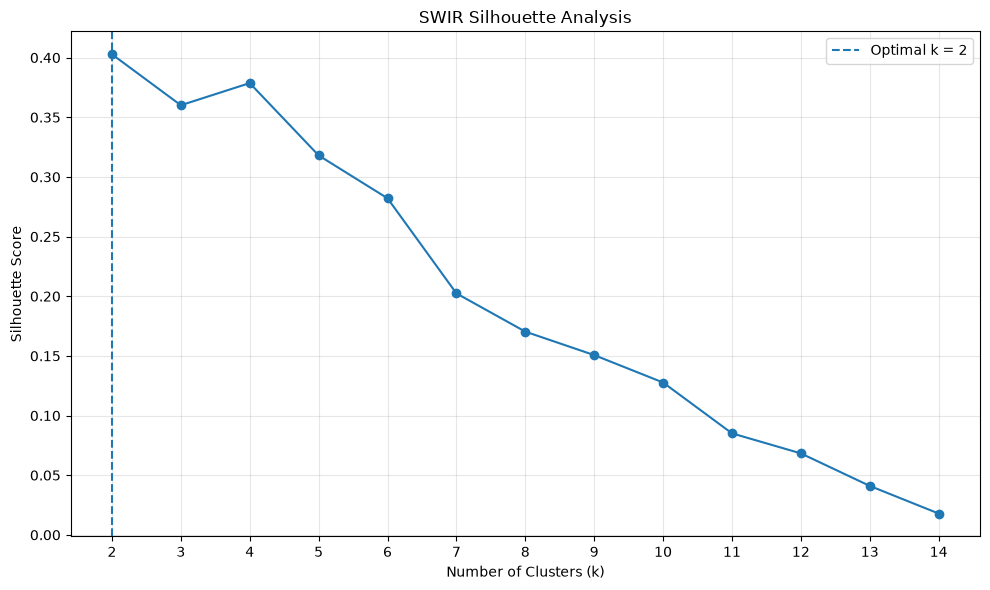

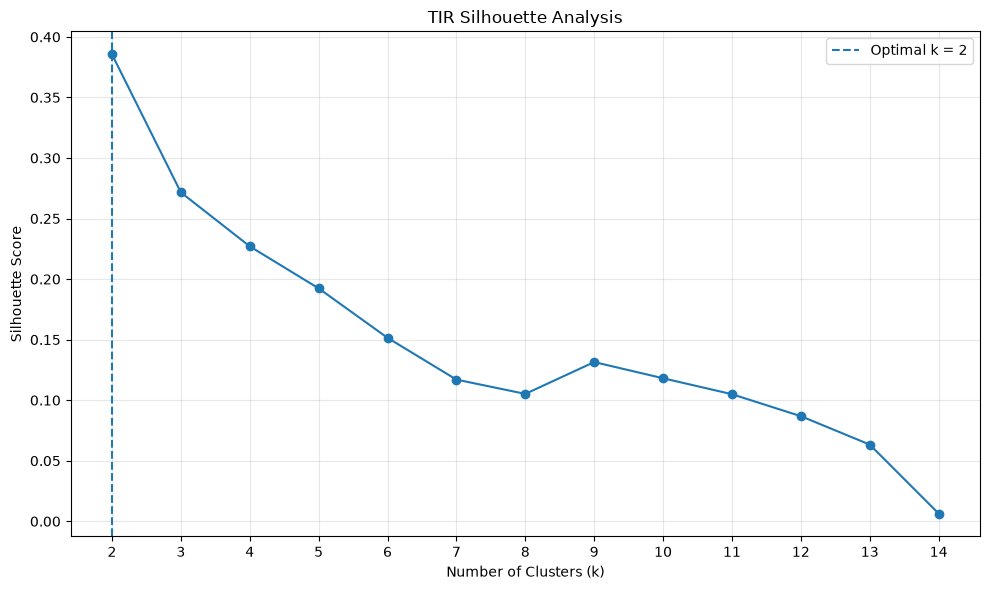

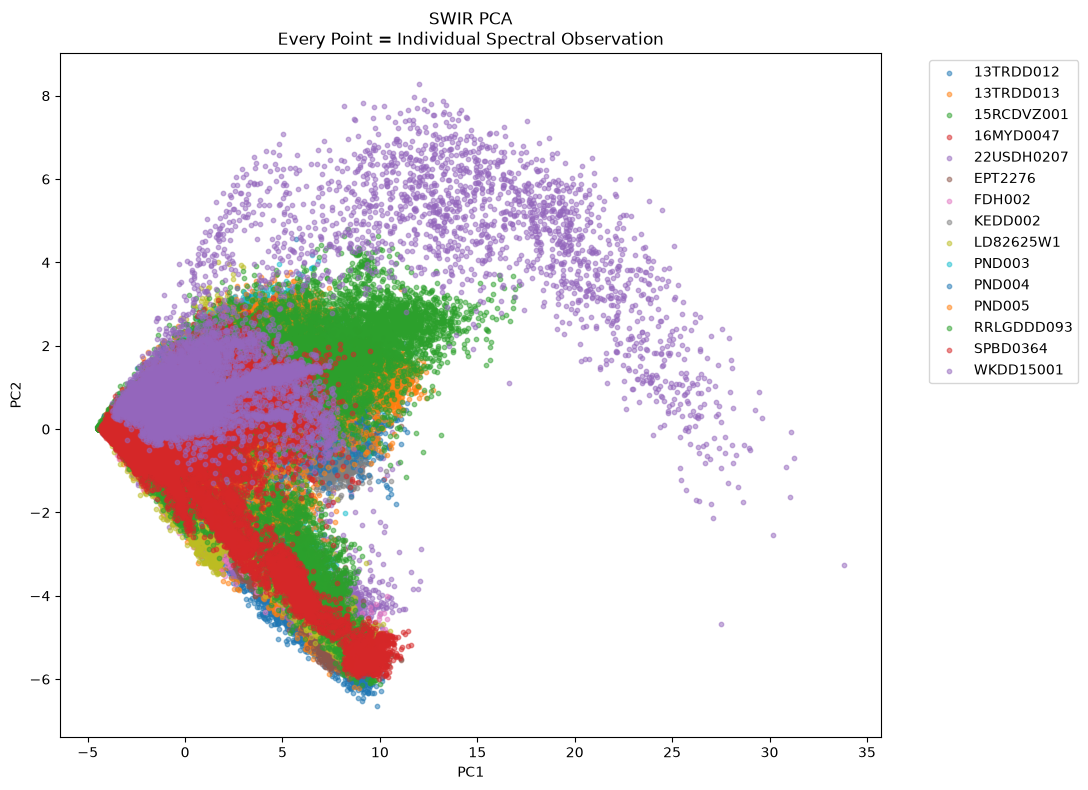

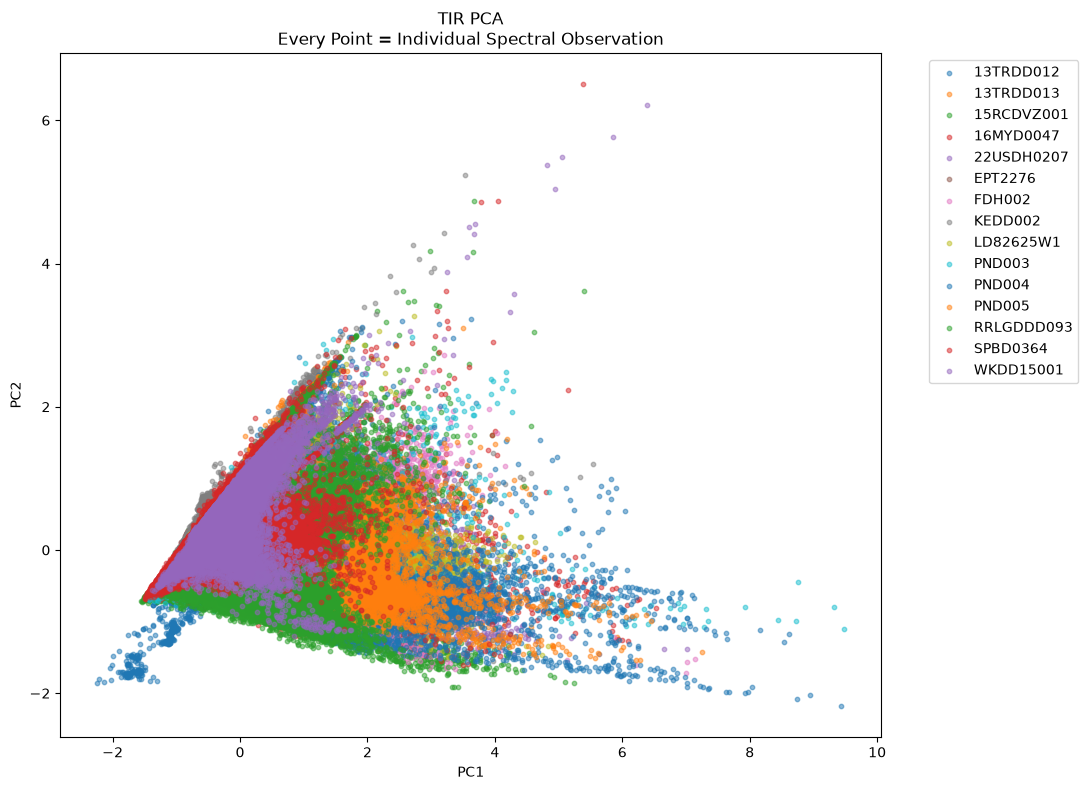

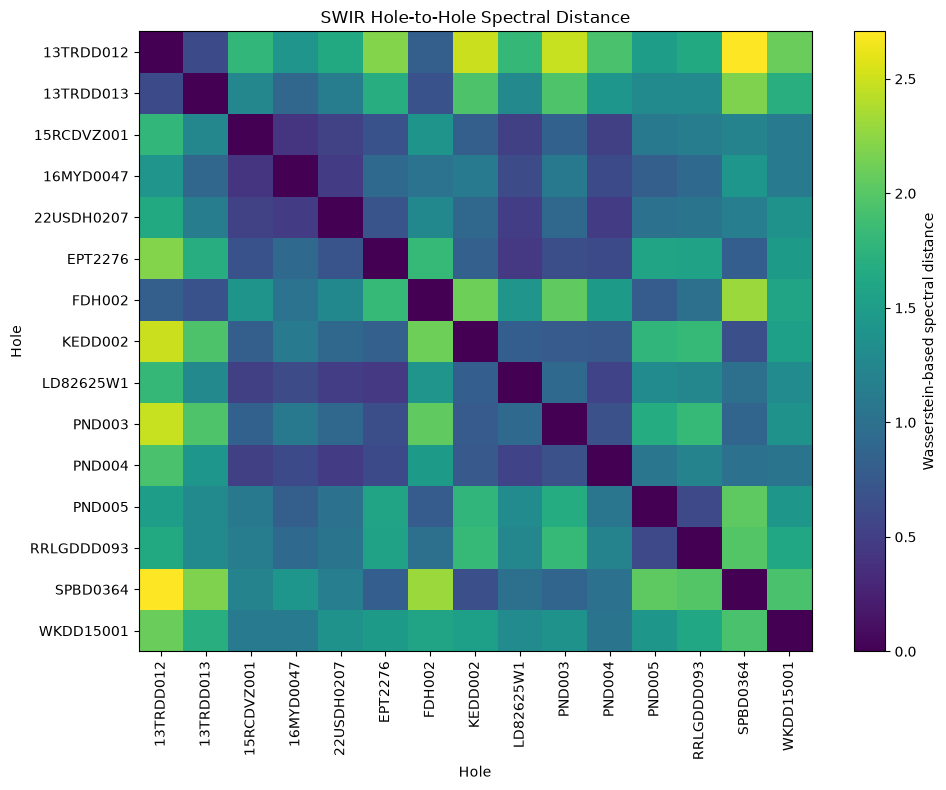

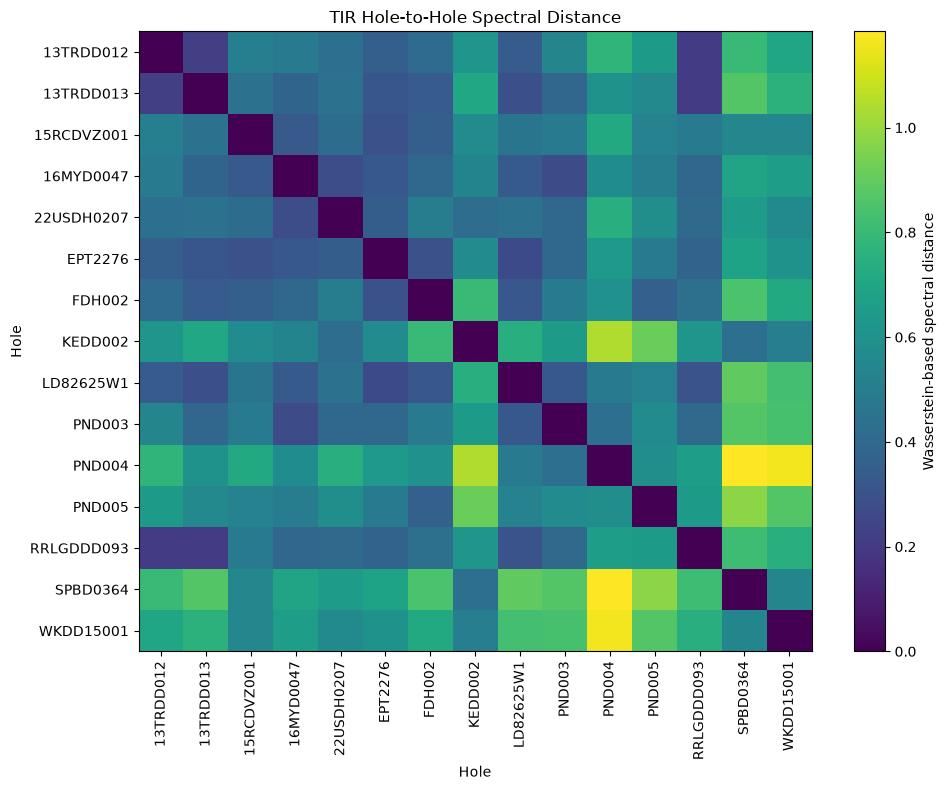



FINAL HOLE-LEVEL CLUSTERING PLOT: SWIR

Hole-level MDS coordinates:
   hole_id      MDS1      MDS2  cluster
15RCDVZ001 -0.096583 -0.214274        0
 16MYD0047  0.147377  0.036647        0
22USDH0207 -0.190586  0.113877        0
   EPT2276 -0.740390 -0.099668        0
   KEDD002 -0.894237 -0.552760        0
 LD82625W1 -0.435735  0.057575        0
    PND003 -0.582849 -0.822066        0
    PND004 -0.225638 -0.369453        0
  SPBD0364 -1.299761 -0.271907        0
 WKDD15001  0.536467 -1.006652        0
 13TRDD012  1.193712  1.070889        1
 13TRDD013  0.704274  0.787015        1
    FDH002  1.028760  0.433221        1
    PND005  0.806470 -0.063418        1
RRLGDDD093  0.048720  0.900973        1


/Users/yeshwanth_g/Desktop/VScode/gswa-hylogger-data-crunch/.venv/lib/python3.14/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/Users/yeshwanth_g/Desktop/VScode/gswa-hylogger-data-crunch/.venv/lib/python3.14/site-packages/sklearn/manifold/_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(


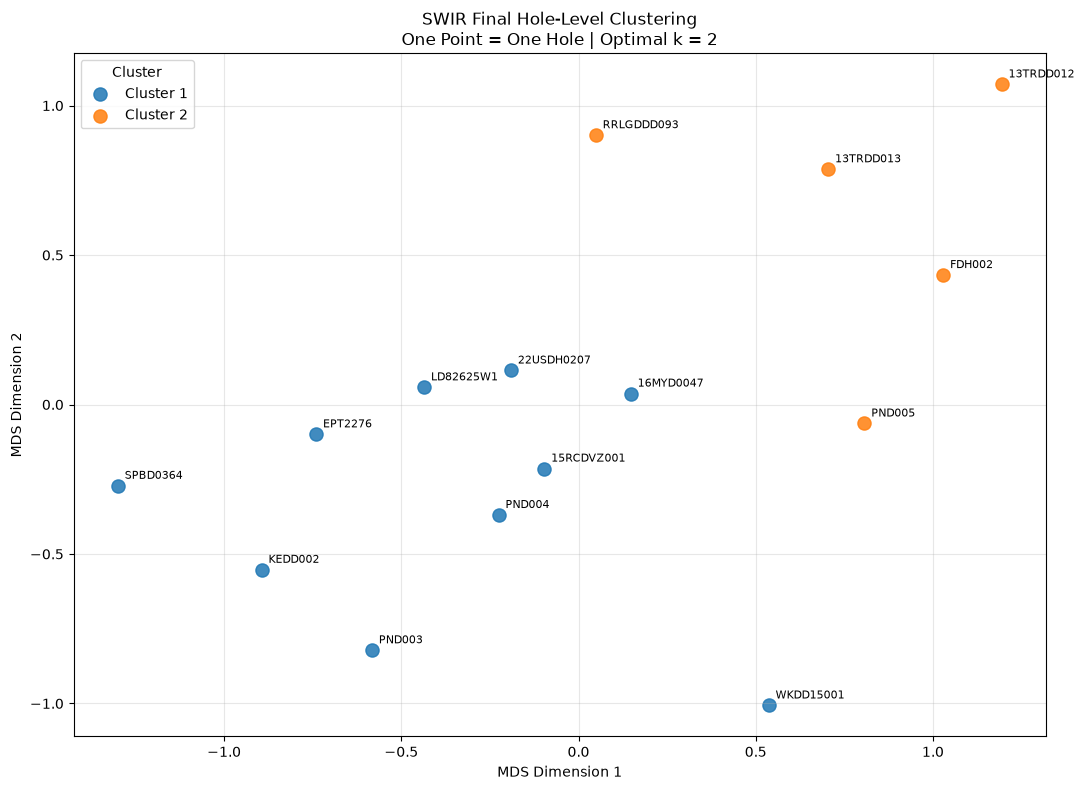



FINAL HOLE-LEVEL CLUSTERING PLOT: TIR

Hole-level MDS coordinates:
   hole_id      MDS1      MDS2  cluster
 13TRDD012 -0.054282  0.337329        0
 13TRDD013  0.123057  0.258531        0
15RCDVZ001 -0.081045 -0.219467        0
 16MYD0047  0.039038 -0.110724        0
22USDH0207 -0.178160  0.023881        0
   EPT2276  0.010014  0.036881        0
    FDH002  0.244132  0.029002        0
 LD82625W1  0.235186  0.173524        0
    PND003  0.258974 -0.102674        0
    PND004  0.640367  0.038990        0
    PND005  0.334681 -0.361898        0
RRLGDDD093  0.031102  0.303940        0
   KEDD002 -0.503974  0.112703        1
  SPBD0364 -0.658955 -0.126586        1
 WKDD15001 -0.440134 -0.393432        1


/Users/yeshwanth_g/Desktop/VScode/gswa-hylogger-data-crunch/.venv/lib/python3.14/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/Users/yeshwanth_g/Desktop/VScode/gswa-hylogger-data-crunch/.venv/lib/python3.14/site-packages/sklearn/manifold/_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(


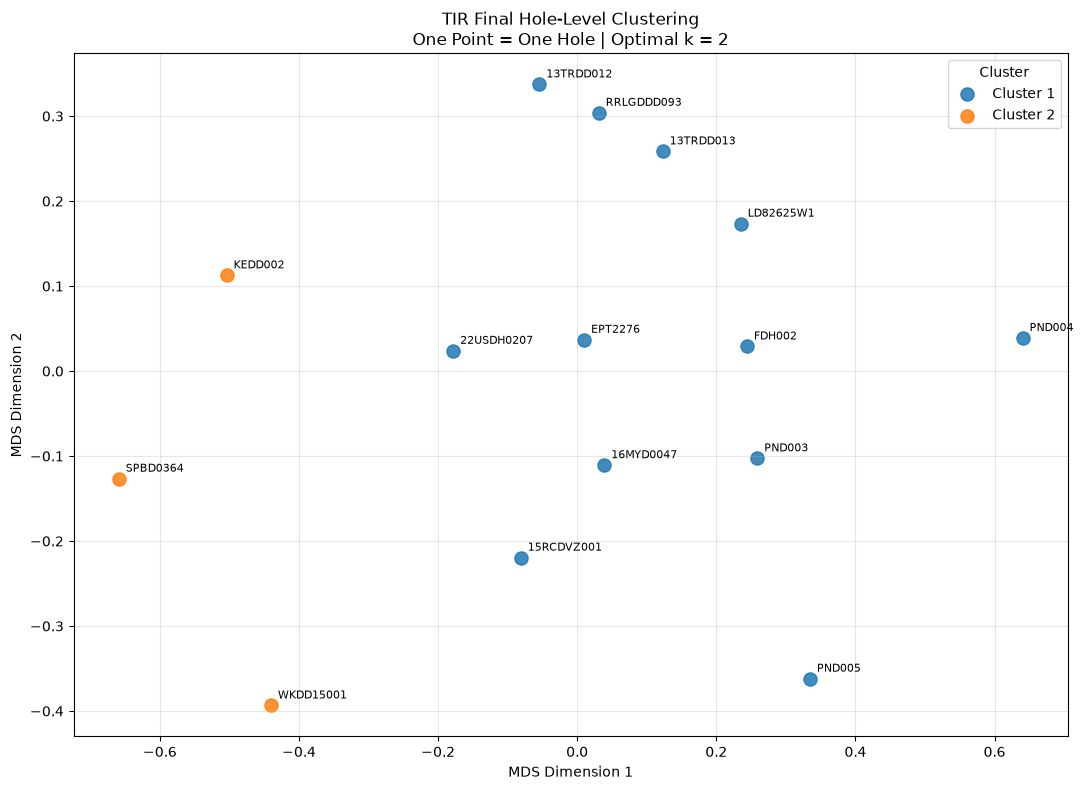




FINAL RESULTS

SWIR
------------------------------------------------------------------------------------------
Original spectral matrix: (1027111, 531)
Individual PCA observations: (1027111, 14)
Number of holes: 15
PCA components retained: 4
Variance retained: 99.0231%
Hole distance matrix: (15, 15)
Cluster evaluation range: 2 to 14
Optimal cluster count: 2
Highest silhouette score: 0.402798
Final silhouette score: 0.402798

SWIR hole clusters:
   hole_id  SWIR_cluster
15RCDVZ001             0
 16MYD0047             0
22USDH0207             0
   EPT2276             0
   KEDD002             0
 LD82625W1             0
    PND003             0
    PND004             0
  SPBD0364             0
 WKDD15001             0
 13TRDD012             1
 13TRDD013             1
    FDH002             1
    PND005             1
RRLGDDD093             1

TIR
------------------------------------------------------------------------------------------
Original spectral matrix: (1027111, 341)
Individual 

In [86]:
# ============================================================
# PCA + HOLE-LEVEL SPECTRAL CLUSTERING
#
# SWIR and TIR are processed separately.
#
# COMPLETE WORKFLOW:
#
# Individual spectra
#       |
#       v
# PCA (99% variance)
#       |
#       v
# Individual PCA observations
#       |
#       v
# Hole-level PCA distributions
#       |
#       v
# Wasserstein distance between holes
#       |
#       v
# Hole-to-hole distance matrix
#       |
#       v
# Test multiple cluster counts
#       |
#       v
# Silhouette score for every k
#       |
#       v
# Select k with highest silhouette score
#       |
#       v
# Final Agglomerative Clustering
#       |
#       v
# MDS visualization of hole distances
#       |
#       v
# FINAL CLUSTERING PLOT
#
# IMPORTANT:
#
# The final clustering plot contains:
#
#     ONE POINT = ONE HOLE
#
# NOT:
#
#     ONE POINT = ONE SPECTRUM
#
# The colors represent the final hole-level clusters.
#
# ============================================================


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.manifold import MDS

from scipy.stats import wasserstein_distance


# ============================================================
# 1. PCA variance retention
# ============================================================


PCA_VARIANCE = 0.99


# ------------------------------------------------------------
# Range of k values for silhouette analysis
# ------------------------------------------------------------

MIN_K = 2
MAX_K = 40


# ------------------------------------------------------------
# MDS settings
#
# MDS converts the hole-to-hole distance matrix into a
# two-dimensional representation for visualization.
# ------------------------------------------------------------

MDS_RANDOM_STATE = 42


# ============================================================
# 2. PCA FUNCTION
# ============================================================

def perform_pca(
    X,
    metadata,
    wavelengths,
    sensor_name,
    variance_threshold=0.99
):

    print("\n")
    print("=" * 90)
    print(f"PCA ANALYSIS: {sensor_name}")
    print("=" * 90)

    # ========================================================
    # 2.1 INPUT VALIDATION
    # ========================================================

    X = np.asarray(
        X,
        dtype=np.float64
    )

    if X.ndim != 2:

        raise ValueError(
            f"{sensor_name}: X must be a 2D matrix."
        )


    if len(X) != len(metadata):

        raise ValueError(
            f"{sensor_name}: number of spectra "
            f"does not match metadata rows."
        )


    if X.shape[1] != len(wavelengths):

        raise ValueError(
            f"{sensor_name}: number of spectral variables "
            f"does not match wavelength count."
        )


    if not np.isfinite(X).all():

        raise ValueError(
            f"{sensor_name}: non-finite spectral values detected."
        )


    # ========================================================
    # 2.2 ORIGINAL DATA INFORMATION
    # ========================================================

    print("\nOriginal spectral matrix:")
    print("Rows    =", X.shape[0])
    print("Columns =", X.shape[1])


    print(
        "\nEvery row represents one individual spectral observation."
    )



    # ========================================================
    # 2.4 FULL PCA
    # ========================================================

    print("\nRunning full PCA...")

    pca_full = PCA()

    X_pca_full = pca_full.fit_transform(X)


    # ========================================================
    # 2.5 EXPLAINED VARIANCE
    # ========================================================

    explained_variance = (
        pca_full.explained_variance_ratio_
    )


    cumulative_variance = np.cumsum(
        explained_variance
    )


    # ========================================================
    # 2.6 DETERMINE NUMBER OF COMPONENTS
    # ========================================================

    n_components = (

        np.searchsorted(
            cumulative_variance,
            variance_threshold
        )

        + 1

    )


    n_components = min(
        n_components,
        X_pca_full.shape[1]
    )


    print("\nPCA variance retention:")

    print(
        f"Requested variance : "
        f"{variance_threshold:.2%}"
    )

    print(
        "Number of PCs retained:",
        n_components
    )

    print(
        "Actual variance retained:",
        f"{cumulative_variance[n_components - 1]:.4%}"
    )


    # ========================================================
    # 2.7 FINAL PCA
    # ========================================================

    pca = PCA(
        n_components=n_components
    )


    X_pca = pca.fit_transform(X)


    # ========================================================
    # 2.8 PCA COLUMN NAMES
    # ========================================================

    pc_columns = [

        f"PC{i + 1}"

        for i in range(n_components)

    ]


    pca_scores = pd.DataFrame(

        X_pca,

        columns=pc_columns

    )


    # ========================================================
    # 2.9 ATTACH ORIGINAL METADATA
    # ========================================================

    pca_data = pd.concat(

        [

            metadata.reset_index(drop=True),

            pca_scores

        ],

        axis=1

    )


    # ========================================================
    # 2.10 VERIFY ROW ALIGNMENT
    # ========================================================

    if len(pca_data) != len(X):

        raise ValueError(
            f"{sensor_name}: PCA row alignment failed."
        )


    # ========================================================
    # 2.11 PRINT PCA INFORMATION
    # ========================================================

    print("\nPCA score matrix:")

    print(
        "Rows    =",
        X_pca.shape[0]
    )

    print(
        "Columns =",
        X_pca.shape[1]
    )


    print("\nFirst principal components:")

    for i in range(
        min(5, n_components)
    ):

        print(
            f"PC{i + 1}: "
            f"{explained_variance[i]:.6f}"
        )


    # ========================================================
    # 2.12 RETURN
    # ========================================================

    return {

        "pca": pca,

        "pca_data": pca_data,

        "pca_scores": X_pca,

        "explained_variance":
            explained_variance,

        "cumulative_variance":
            cumulative_variance,

        "n_components":
            n_components

    }


# ============================================================
# 3. RUN PCA ON SWIR
# ============================================================

swir_pca_result = perform_pca(

    X_SWIR,

    SWIR_METADATA,

    SWIR_WAVELENGTHS,

    "SWIR",

    PCA_VARIANCE

)


SWIR_PCA_MODEL = (
    swir_pca_result["pca"]
)


SWIR_PCA_DATA = (
    swir_pca_result["pca_data"]
)


SWIR_PCA_SCORES = (
    swir_pca_result["pca_scores"]
)


# ============================================================
# 4. RUN PCA ON TIR
# ============================================================

tir_pca_result = perform_pca(

    X_TIR,

    TIR_METADATA,

    TIR_WAVELENGTHS,

    "TIR",

    PCA_VARIANCE

)


TIR_PCA_MODEL = (
    tir_pca_result["pca"]
)


TIR_PCA_DATA = (
    tir_pca_result["pca_data"]
)


TIR_PCA_SCORES = (
    tir_pca_result["pca_scores"]
)


# ============================================================
# 5. PCA VARIANCE TABLE
# ============================================================

def create_variance_table(
    pca_result,
    sensor_name
):

    n = pca_result["n_components"]

    variance = (
        pca_result[
            "explained_variance"
        ][:n]
    )

    cumulative = (
        pca_result[
            "cumulative_variance"
        ][:n]
    )


    table = pd.DataFrame({

        "Component": [

            f"PC{i + 1}"

            for i in range(n)

        ],

        "Explained_Variance":
            variance,

        "Cumulative_Variance":
            cumulative

    })


    print("\n")
    print("=" * 90)
    print(
        f"{sensor_name} PCA VARIANCE TABLE"
    )
    print("=" * 90)

    print(
        table.to_string(
            index=False
        )
    )


    return table


SWIR_VARIANCE_TABLE = (
    create_variance_table(
        swir_pca_result,
        "SWIR"
    )
)


TIR_VARIANCE_TABLE = (
    create_variance_table(
        tir_pca_result,
        "TIR"
    )
)


# ============================================================
# 6. VERIFY INDIVIDUAL PCA OBSERVATIONS
# ============================================================

print("\n")
print("=" * 90)
print("INDIVIDUAL PCA OBSERVATIONS")
print("=" * 90)


print("\nSWIR:")

display_columns = [
    "hole_id",
    "depth_m",
    "PC1"
]

if "PC2" in SWIR_PCA_DATA.columns:

    display_columns.append("PC2")


print(
    SWIR_PCA_DATA[
        display_columns
    ].head(10)
)


print("\nTIR:")

display_columns = [
    "hole_id",
    "depth_m",
    "PC1"
]

if "PC2" in TIR_PCA_DATA.columns:

    display_columns.append("PC2")


print(
    TIR_PCA_DATA[
        display_columns
    ].head(10)
)


# ============================================================
# 7. CHECK NUMBER OF SPECTRA PER HOLE
# ============================================================

def print_hole_observation_counts(
    pca_data,
    sensor_name
):

    counts = (

        pca_data

        .groupby("hole_id")

        .size()

        .sort_index()

    )


    print("\n")
    print("=" * 90)
    print(
        f"{sensor_name} INDIVIDUAL SPECTRA PER HOLE"
    )
    print("=" * 90)


    print(counts)


    print(
        "\nNumber of holes:",
        len(counts)
    )


    print(
        "Total individual observations:",
        counts.sum()
    )


    return counts


SWIR_HOLE_COUNTS = (
    print_hole_observation_counts(
        SWIR_PCA_DATA,
        "SWIR"
    )
)


TIR_HOLE_COUNTS = (
    print_hole_observation_counts(
        TIR_PCA_DATA,
        "TIR"
    )
)


# ============================================================
# 8. SELECT PCs FOR HOLE COMPARISON
# ============================================================

def select_pca_components(
    pca_data
):

    pc_columns = [

        column

        for column in pca_data.columns

        if column.startswith("PC")

    ]


    if len(pc_columns) == 0:

        raise ValueError(
            "No PCA components found."
        )


    return pc_columns


SWIR_DISTANCE_PCS = (
    select_pca_components(
        SWIR_PCA_DATA
    )
)


TIR_DISTANCE_PCS = (
    select_pca_components(
        TIR_PCA_DATA
    )
)


print("\n")
print("=" * 90)
print("PCA COMPONENTS USED FOR HOLE COMPARISON")
print("=" * 90)


print(
    "SWIR:",
    len(SWIR_DISTANCE_PCS),
    "components"
)


print(
    "TIR:",
    len(TIR_DISTANCE_PCS),
    "components"
)


# ============================================================
# 9. CALCULATE HOLE-TO-HOLE SPECTRAL DISTANCES
# ============================================================

def calculate_hole_distance_matrix(
    pca_data,
    pc_columns,
    sensor_name
):

    print("\n")
    print("=" * 90)
    print(
        f"HOLE-TO-HOLE SPECTRAL DISTANCE: "
        f"{sensor_name}"
    )
    print("=" * 90)


    # --------------------------------------------------------
    # Hole list
    # --------------------------------------------------------

    holes = sorted(

        pca_data[
            "hole_id"
        ]

        .dropna()

        .unique()

    )


    n_holes = len(holes)


    print(
        "\nNumber of holes:",
        n_holes
    )


    print(
        "Number of PCA dimensions:",
        len(pc_columns)
    )


    # --------------------------------------------------------
    # Pre-store observations
    # --------------------------------------------------------

    hole_pc_values = {}


    for hole_id in holes:

        hole_rows = (
            pca_data[
                pca_data["hole_id"] == hole_id
            ]
        )


        hole_pc_values[hole_id] = {}


        for pc in pc_columns:

            values = (

                hole_rows[pc]

                .to_numpy(
                    dtype=np.float64
                )

            )


            if len(values) == 0:

                raise ValueError(
                    f"{sensor_name}: "
                    f"hole {hole_id} has no "
                    f"observations for {pc}."
                )


            if not np.isfinite(values).all():

                raise ValueError(
                    f"{sensor_name}: "
                    f"non-finite PC values in "
                    f"hole {hole_id}."
                )


            hole_pc_values[
                hole_id
            ][pc] = values


    # --------------------------------------------------------
    # Distance matrix
    # --------------------------------------------------------

    distance_matrix = np.zeros(

        (
            n_holes,
            n_holes
        ),

        dtype=np.float64

    )


    # --------------------------------------------------------
    # Pairwise hole distances
    # --------------------------------------------------------

    for i in range(n_holes):

        hole_i = holes[i]


        for j in range(
            i + 1,
            n_holes
        ):

            hole_j = holes[j]


            pc_distances = []


            # ------------------------------------------------
            # Compare distributions for every PC
            # ------------------------------------------------

            for pc in pc_columns:

                values_i = (
                    hole_pc_values[
                        hole_i
                    ][pc]
                )


                values_j = (
                    hole_pc_values[
                        hole_j
                    ][pc]
                )


                distance = (

                    wasserstein_distance(

                        values_i,

                        values_j

                    )

                )


                pc_distances.append(
                    distance
                )


            # ------------------------------------------------
            # Combine PC-wise distances
            # ------------------------------------------------

            pc_distances = np.asarray(
                pc_distances,
                dtype=np.float64
            )


            combined_distance = np.sqrt(

                np.sum(
                    pc_distances ** 2
                )

            )


            distance_matrix[i, j] = (
                combined_distance
            )


            distance_matrix[j, i] = (
                combined_distance
            )


    distance_df = pd.DataFrame(

        distance_matrix,

        index=holes,

        columns=holes

    )


    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    if not np.isfinite(
        distance_matrix
    ).all():

        raise ValueError(
            f"{sensor_name}: "
            "non-finite distances detected."
        )


    if not np.allclose(
        distance_matrix,
        distance_matrix.T
    ):

        raise ValueError(
            f"{sensor_name}: "
            "distance matrix is not symmetric."
        )


    if not np.allclose(
        np.diag(distance_matrix),
        0
    ):

        raise ValueError(
            f"{sensor_name}: "
            "distance matrix diagonal is not zero."
        )


    print(
        "\nDistance matrix shape:",
        distance_df.shape
    )


    return (
        distance_df,
        holes
    )


# ============================================================
# 10. SWIR HOLE DISTANCE MATRIX
# ============================================================

(
    SWIR_HOLE_DISTANCE_MATRIX,
    SWIR_HOLES
) = calculate_hole_distance_matrix(

    SWIR_PCA_DATA,

    SWIR_DISTANCE_PCS,

    "SWIR"

)


# ============================================================
# 11. TIR HOLE DISTANCE MATRIX
# ============================================================

(
    TIR_HOLE_DISTANCE_MATRIX,
    TIR_HOLES
) = calculate_hole_distance_matrix(

    TIR_PCA_DATA,

    TIR_DISTANCE_PCS,

    "TIR"

)


# ============================================================
# 12. PRINT DISTANCE MATRICES
# ============================================================

print("\n")
print("=" * 90)
print("SWIR HOLE-TO-HOLE DISTANCE MATRIX")
print("=" * 90)

print(
    SWIR_HOLE_DISTANCE_MATRIX
)


print("\n")
print("=" * 90)
print("TIR HOLE-TO-HOLE DISTANCE MATRIX")
print("=" * 90)

print(
    TIR_HOLE_DISTANCE_MATRIX
)


# ============================================================
# 13. EVALUATE DIFFERENT NUMBERS OF CLUSTERS
# ============================================================

def evaluate_cluster_counts(

    distance_df,

    sensor_name,

    min_k= MIN_K,

    max_k= MAX_K

):

    distance_matrix = (
        distance_df.to_numpy(
            dtype=np.float64
        )
    )


    n_holes = len(distance_df)


    # --------------------------------------------------------
    # Validate requested range
    # --------------------------------------------------------

    if n_holes < 3:

        raise ValueError(
            f"{sensor_name}: at least 3 holes "
            "are required for cluster-count evaluation."
        )


    if min_k < 2:

        raise ValueError(
            "MIN_K must be at least 2."
        )


    max_allowed_k = min(
        max_k,
        n_holes - 1
    )


    if min_k > max_allowed_k:

        raise ValueError(
            f"{sensor_name}: invalid cluster range. "
            f"Requested {min_k}-{max_k}, but only "
            f"{n_holes} holes are available."
        )


    results = []


    print("\n")
    print("=" * 90)
    print(
        f"{sensor_name} CLUSTER COUNT EVALUATION"
    )
    print("=" * 90)


    print(
        f"\nTesting k values from "
        f"{min_k} to {max_allowed_k}."
    )


    # --------------------------------------------------------
    # Test every k
    # --------------------------------------------------------

    for k in range(
        min_k,
        max_allowed_k + 1
    ):

        model = AgglomerativeClustering(

            n_clusters=k,

            metric="precomputed",

            linkage="average"

        )


        labels = model.fit_predict(
            distance_matrix
        )


        # ----------------------------------------------------
        # Silhouette score
        # ----------------------------------------------------

        score = silhouette_score(

            distance_matrix,

            labels,

            metric="precomputed"

        )


        results.append({

            "n_clusters": k,

            "silhouette_score": score

        })


    # --------------------------------------------------------
    # Create evaluation table
    # --------------------------------------------------------

    results_df = pd.DataFrame(
        results
    )


    print(
        results_df.to_string(
            index=False
        )
    )


    # --------------------------------------------------------
    # Find optimal k
    # --------------------------------------------------------

    optimal_index = (
        results_df[
            "silhouette_score"
        ].idxmax()
    )


    optimal_k = int(

        results_df.loc[
            optimal_index,
            "n_clusters"
        ]

    )


    optimal_score = float(

        results_df.loc[
            optimal_index,
            "silhouette_score"
        ]

    )


    # --------------------------------------------------------
    # Print optimal result
    # --------------------------------------------------------

    print("\n" + "-" * 90)

    print(
        f"{sensor_name} OPTIMAL CLUSTER COUNT"
    )

    print("-" * 90)

    print(
        "Optimal k:",
        optimal_k
    )

    print(
        "Highest silhouette score:",
        f"{optimal_score:.6f}"
    )

    print("-" * 90)


    return (
        results_df,
        optimal_k,
        optimal_score
    )


# ============================================================
# 14. SWIR CLUSTER COUNT EVALUATION
# ============================================================

(
    SWIR_CLUSTER_EVALUATION,
    OPTIMAL_K_SWIR,
    OPTIMAL_SWIR_SILHOUETTE
) = evaluate_cluster_counts(

    SWIR_HOLE_DISTANCE_MATRIX,

    "SWIR",

    MIN_K,

    MAX_K

)


# ============================================================
# 15. TIR CLUSTER COUNT EVALUATION
# ============================================================

(
    TIR_CLUSTER_EVALUATION,
    OPTIMAL_K_TIR,
    OPTIMAL_TIR_SILHOUETTE
) = evaluate_cluster_counts(

    TIR_HOLE_DISTANCE_MATRIX,

    "TIR",

    MIN_K,

    MAX_K

)


# ============================================================
# 16. FINAL CLUSTERING USING OPTIMAL K
# ============================================================


def cluster_holes_from_distance(

    distance_df,

    sensor_name,

    n_clusters

):

    print("\n")
    print("=" * 90)
    print(
        f"FINAL CLUSTERING OF HOLES: {sensor_name}"
    )
    print("=" * 90)


    holes = (
        distance_df.index.to_list()
    )


    distance_matrix = (
        distance_df.to_numpy(
            dtype=np.float64
        )
    )


    # ========================================================
    # VALIDATION
    # ========================================================

    if n_clusters < 2:

        raise ValueError(
            "Number of clusters must be >= 2."
        )


    if n_clusters >= len(holes):

        raise ValueError(
            "Number of clusters must be "
            "smaller than number of holes."
        )


    # ========================================================
    # PRINT SELECTED K
    # ========================================================

    print(
        "\nSelected optimal number of clusters:",
        n_clusters
    )


    # ========================================================
    # AGGLOMERATIVE CLUSTERING
    # ========================================================

    model = AgglomerativeClustering(

        n_clusters=n_clusters,

        metric="precomputed",

        linkage="average"

    )


    labels = model.fit_predict(
        distance_matrix
    )


    # ========================================================
    # RESULT
    # ========================================================

    result = pd.DataFrame({

        "hole_id":
            holes,

        f"{sensor_name}_cluster":
            labels

    })


    # ========================================================
    # PRINT
    # ========================================================

    print("\nHole cluster assignments:")


    print(

        result

        .sort_values(
            f"{sensor_name}_cluster"
        )

        .to_string(
            index=False
        )

    )


    print("\nCluster sizes:")


    print(

        result[
            f"{sensor_name}_cluster"
        ]

        .value_counts()

        .sort_index()

    )


    return (
        result,
        model
    )


# ============================================================
# 17. FINAL SWIR CLUSTERING
# ============================================================

(
    SWIR_HOLE_CLUSTERS,
    SWIR_CLUSTER_MODEL
) = cluster_holes_from_distance(

    SWIR_HOLE_DISTANCE_MATRIX,

    "SWIR",

    OPTIMAL_K_SWIR

)


# ============================================================
# 18. FINAL TIR CLUSTERING
# ============================================================

(
    TIR_HOLE_CLUSTERS,
    TIR_CLUSTER_MODEL
) = cluster_holes_from_distance(

    TIR_HOLE_DISTANCE_MATRIX,

    "TIR",

    OPTIMAL_K_TIR

)


# ============================================================
# 19. VERIFY FINAL SILHOUETTE SCORES
# ============================================================

def calculate_final_silhouette(

    distance_matrix,

    labels,

    sensor_name

):

    unique_labels = np.unique(
        labels
    )


    if len(unique_labels) < 2:

        return np.nan


    if len(unique_labels) >= len(labels):

        return np.nan


    score = silhouette_score(

        distance_matrix,

        labels,

        metric="precomputed"

    )


    print(
        f"{sensor_name} final silhouette score:",
        f"{score:.6f}"
    )


    return score


SWIR_SILHOUETTE = (
    calculate_final_silhouette(

        SWIR_HOLE_DISTANCE_MATRIX.to_numpy(),

        SWIR_HOLE_CLUSTERS[
            "SWIR_cluster"
        ].to_numpy(),

        "SWIR"

    )
)


TIR_SILHOUETTE = (
    calculate_final_silhouette(

        TIR_HOLE_DISTANCE_MATRIX.to_numpy(),

        TIR_HOLE_CLUSTERS[
            "TIR_cluster"
        ].to_numpy(),

        "TIR"

    )
)


# ============================================================
# 21. PLOT SILHOUETTE SCORE VS NUMBER OF CLUSTERS
# ============================================================

def plot_cluster_evaluation(

    evaluation_df,

    optimal_k,

    sensor_name

):

    plt.figure(
        figsize=(10, 6)
    )


    plt.plot(

        evaluation_df[
            "n_clusters"
        ],

        evaluation_df[
            "silhouette_score"
        ],

        marker="o"

    )


    plt.axvline(

        optimal_k,

        linestyle="--",

        label=f"Optimal k = {optimal_k}"

    )


    plt.xlabel(
        "Number of Clusters (k)"
    )


    plt.ylabel(
        "Silhouette Score"
    )


    plt.title(

        f"{sensor_name} "
        "Silhouette Analysis"

    )


    plt.xticks(
        evaluation_df[
            "n_clusters"
        ]
    )


    plt.legend()


    plt.grid(
        True,
        alpha=0.3
    )


    plt.tight_layout()

    plt.show()


# ============================================================
# 22. SWIR SILHOUETTE PLOT
# ============================================================

plot_cluster_evaluation(

    SWIR_CLUSTER_EVALUATION,

    OPTIMAL_K_SWIR,

    "SWIR"

)


# ============================================================
# 23. TIR SILHOUETTE PLOT
# ============================================================

plot_cluster_evaluation(

    TIR_CLUSTER_EVALUATION,

    OPTIMAL_K_TIR,

    "TIR"

)


# ============================================================
# 24. PLOT INDIVIDUAL PCA OBSERVATIONS
# ============================================================

def plot_individual_pca(

    pca_data,

    sensor_name

):

    if not (

        "PC1" in pca_data.columns

        and

        "PC2" in pca_data.columns

    ):

        print(
            f"{sensor_name}: "
            "PC1 and PC2 unavailable."
        )

        return


    plt.figure(
        figsize=(11, 8)
    )


    for hole_id, group in (

        pca_data

        .groupby("hole_id")

    ):

        plt.scatter(

            group["PC1"],

            group["PC2"],

            s=10,

            alpha=0.5,

            label=str(hole_id)

        )


    plt.xlabel(
        "PC1"
    )


    plt.ylabel(
        "PC2"
    )


    plt.title(

        f"{sensor_name} PCA\n"
        "Every Point = Individual Spectral Observation"

    )


    if pca_data[
        "hole_id"
    ].nunique() <= 20:

        plt.legend(

            bbox_to_anchor=(1.05, 1),

            loc="upper left"

        )


    plt.tight_layout()

    plt.show()


# ============================================================
# 25. SWIR PCA PLOT
# ============================================================

plot_individual_pca(

    SWIR_PCA_DATA,

    "SWIR"

)


# ============================================================
# 26. TIR PCA PLOT
# ============================================================

plot_individual_pca(

    TIR_PCA_DATA,

    "TIR"

)


# ============================================================
# 27. DISTANCE MATRIX HEATMAP
# ============================================================

def plot_distance_matrix(

    distance_df,

    sensor_name

):

    plt.figure(

        figsize=(10, 8)

    )


    plt.imshow(

        distance_df.to_numpy(),

        aspect="auto"

    )


    plt.colorbar(

        label="Wasserstein-based spectral distance"

    )


    plt.xticks(

        range(len(distance_df)),

        distance_df.columns,

        rotation=90

    )


    plt.yticks(

        range(len(distance_df)),

        distance_df.index

    )


    plt.xlabel(
        "Hole"
    )


    plt.ylabel(
        "Hole"
    )


    plt.title(

        f"{sensor_name} "
        "Hole-to-Hole Spectral Distance"

    )


    plt.tight_layout()

    plt.show()


# ============================================================
# 28. SWIR DISTANCE HEATMAP
# ============================================================

plot_distance_matrix(

    SWIR_HOLE_DISTANCE_MATRIX,

    "SWIR"

)


# ============================================================
# 29. TIR DISTANCE HEATMAP
# ============================================================

plot_distance_matrix(

    TIR_HOLE_DISTANCE_MATRIX,

    "TIR"

)


# ============================================================
# 30. FINAL HOLE-LEVEL MDS CLUSTERING PLOT
# ============================================================

def plot_final_hole_clustering(

    distance_df,

    cluster_result,

    sensor_name,

    optimal_k

):

    print("\n")
    print("=" * 90)
    print(
        f"FINAL HOLE-LEVEL CLUSTERING PLOT: {sensor_name}"
    )
    print("=" * 90)


    # --------------------------------------------------------
    # Extract holes
    # --------------------------------------------------------

    holes = (
        distance_df.index.to_list()
    )


    # --------------------------------------------------------
    # Extract final cluster labels
    # --------------------------------------------------------

    cluster_column = (
        f"{sensor_name}_cluster"
    )


    labels = (

        cluster_result

        .set_index("hole_id")

        .loc[
            holes,
            cluster_column
        ]

        .to_numpy()

    )


    # --------------------------------------------------------
    # Verify number of clusters
    # --------------------------------------------------------

    actual_k = (
        len(
            np.unique(labels)
        )
    )


    if actual_k != optimal_k:

        raise ValueError(

            f"{sensor_name}: expected "
            f"{optimal_k} clusters but found "
            f"{actual_k}."

        )


    # --------------------------------------------------------
    # Original hole distance matrix
    # --------------------------------------------------------

    distance_matrix = (

        distance_df

        .to_numpy(
            dtype=np.float64
        )

    )


    # --------------------------------------------------------
    # MDS
    #
    # Convert the hole distance matrix into two dimensions.
    #
    # --------------------------------------------------------

    mds = MDS(

        n_components=2,

        dissimilarity="precomputed",

        random_state=MDS_RANDOM_STATE

    )


    coordinates = mds.fit_transform(
        distance_matrix
    )


    # --------------------------------------------------------
    # Create plotting DataFrame
    # --------------------------------------------------------

    plot_data = pd.DataFrame({

        "hole_id":
            holes,

        "MDS1":
            coordinates[:, 0],

        "MDS2":
            coordinates[:, 1],

        "cluster":
            labels

    })


    # --------------------------------------------------------
    # Print coordinates
    # --------------------------------------------------------

    print("\nHole-level MDS coordinates:")

    print(

        plot_data

        .sort_values(
            "cluster"
        )

        .to_string(
            index=False
        )

    )


    # ========================================================
    # PLOT
    # ========================================================

    plt.figure(
        figsize=(11, 8)
    )


    # --------------------------------------------------------
    # Plot each cluster
    # --------------------------------------------------------

    for cluster_id in sorted(
        plot_data["cluster"].unique()
    ):

        cluster_points = (

            plot_data[
                plot_data["cluster"] == cluster_id
            ]

        )


        plt.scatter(

            cluster_points["MDS1"],

            cluster_points["MDS2"],

            s=90,

            alpha=0.85,

            label=f"Cluster {cluster_id + 1}"

        )


    # --------------------------------------------------------
    # Add hole IDs
    # --------------------------------------------------------

    for _, row in plot_data.iterrows():

        plt.annotate(

            str(row["hole_id"]),

            (
                row["MDS1"],
                row["MDS2"]
            ),

            xytext=(5, 5),

            textcoords="offset points",

            fontsize=8

        )


    # --------------------------------------------------------
    # Labels
    # --------------------------------------------------------

    plt.xlabel(
        "MDS Dimension 1"
    )


    plt.ylabel(
        "MDS Dimension 2"
    )


    plt.title(

        f"{sensor_name} Final Hole-Level Clustering\n"
        f"One Point = One Hole | Optimal k = {optimal_k}"

    )


    plt.legend(
        title="Cluster"
    )


    plt.grid(
        True,
        alpha=0.3
    )


    plt.tight_layout()

    plt.show()


    return plot_data


# ============================================================
# 31. FINAL SWIR HOLE CLUSTERING PLOT
# ============================================================

SWIR_FINAL_CLUSTER_PLOT = (

    plot_final_hole_clustering(

        SWIR_HOLE_DISTANCE_MATRIX,

        SWIR_HOLE_CLUSTERS,

        "SWIR",

        OPTIMAL_K_SWIR

    )

)


# ============================================================
# 32. FINAL TIR HOLE CLUSTERING PLOT
# ============================================================

TIR_FINAL_CLUSTER_PLOT = (

    plot_final_hole_clustering(

        TIR_HOLE_DISTANCE_MATRIX,

        TIR_HOLE_CLUSTERS,

        "TIR",

        OPTIMAL_K_TIR

    )

)


# ============================================================
# 33. FINAL RESULTS
# ============================================================

print("\n\n")
print("=" * 90)
print("FINAL RESULTS")
print("=" * 90)


# ------------------------------------------------------------
# SWIR
# ------------------------------------------------------------

print("\nSWIR")
print("-" * 90)


print(
    "Original spectral matrix:",
    X_SWIR.shape
)


print(
    "Individual PCA observations:",
    SWIR_PCA_DATA.shape
)


print(
    "Number of holes:",
    len(SWIR_HOLES)
)


print(
    "PCA components retained:",
    len(SWIR_DISTANCE_PCS)
)


print(
    "Variance retained:",
    f"{swir_pca_result['cumulative_variance'][swir_pca_result['n_components'] - 1]:.4%}"
)


print(
    "Hole distance matrix:",
    SWIR_HOLE_DISTANCE_MATRIX.shape
)


print(
    "Cluster evaluation range:",
    f"{MIN_K} to {min(MAX_K, len(SWIR_HOLES) - 1)}"
)


print(
    "Optimal cluster count:",
    OPTIMAL_K_SWIR
)


print(
    "Highest silhouette score:",
    f"{OPTIMAL_SWIR_SILHOUETTE:.6f}"
)


print(
    "Final silhouette score:",
    f"{SWIR_SILHOUETTE:.6f}"
)


print("\nSWIR hole clusters:")


print(

    SWIR_HOLE_CLUSTERS

    .sort_values(
        "SWIR_cluster"
    )

    .to_string(
        index=False
    )

)


# ------------------------------------------------------------
# TIR
# ------------------------------------------------------------

print("\nTIR")
print("-" * 90)


print(
    "Original spectral matrix:",
    X_TIR.shape
)


print(
    "Individual PCA observations:",
    TIR_PCA_DATA.shape
)


print(
    "Number of holes:",
    len(TIR_HOLES)
)


print(
    "PCA components retained:",
    len(TIR_DISTANCE_PCS)
)


print(
    "Variance retained:",
    f"{tir_pca_result['cumulative_variance'][tir_pca_result['n_components'] - 1]:.4%}"
)


print(
    "Hole distance matrix:",
    TIR_HOLE_DISTANCE_MATRIX.shape
)


print(
    "Cluster evaluation range:",
    f"{MIN_K} to {min(MAX_K, len(TIR_HOLES) - 1)}"
)


print(
    "Optimal cluster count:",
    OPTIMAL_K_TIR
)


print(
    "Highest silhouette score:",
    f"{OPTIMAL_TIR_SILHOUETTE:.6f}"
)


print(
    "Final silhouette score:",
    f"{TIR_SILHOUETTE:.6f}"
)


print("\nTIR hole clusters:")


print(

    TIR_HOLE_CLUSTERS

    .sort_values(
        "TIR_cluster"
    )

    .to_string(
        index=False
    )

)


# ============================================================
# 34. FINAL SUMMARY
# ============================================================

print("\n\n")
print("=" * 90)
print("AUTOMATIC CLUSTER SELECTION SUMMARY")
print("=" * 90)


print("\nSWIR")
print(
    f"Optimal k = {OPTIMAL_K_SWIR}"
)

print(
    f"Silhouette score = "
    f"{OPTIMAL_SWIR_SILHOUETTE:.6f}"
)


print(
    f"Final number of hole clusters = "
    f"{SWIR_HOLE_CLUSTERS['SWIR_cluster'].nunique()}"
)


print("\nTIR")
print(
    f"Optimal k = {OPTIMAL_K_TIR}"
)

print(
    f"Silhouette score = "
    f"{OPTIMAL_TIR_SILHOUETTE:.6f}"
)


print(
    f"Final number of hole clusters = "
    f"{TIR_HOLE_CLUSTERS['TIR_cluster'].nunique()}"
)


print("\n")
print("=" * 90)
print("CLUSTERING COMPLETE")
print("=" * 90)